In [6]:
import os
base = '/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset'
print(os.listdir(base))

['Lung_Opacity.metadata.xlsx', 'Normal.metadata.xlsx', 'README.md.txt', 'COVID.metadata.xlsx', 'Normal', 'Lung_Opacity', 'Viral Pneumonia.metadata.xlsx', 'Viral Pneumonia', 'COVID']


In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split

classes = ['COVID', 'Normal', 'Lung_Opacity', 'Viral Pneumonia']

data = []
for c in classes:
    img_dir = os.path.join(base, c, 'images')
    for fname in os.listdir(img_dir):
        data.append({'filepath': os.path.join(img_dir, fname), 'label': c})

df = pd.DataFrame(data)
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

datagen_mobilenet = ImageDataGenerator(preprocessing_function=preprocess_input)

train_gen_mobilenet = datagen_mobilenet.flow_from_dataframe(
    train_df, x_col='filepath', y_col='label',
    target_size=(224, 224), batch_size=32, class_mode='categorical'
)

val_gen_mobilenet = datagen_mobilenet.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=(224, 224), batch_size=32, class_mode='categorical'
)

eval_gen_mobilenet = datagen_mobilenet.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=(224, 224), batch_size=32, class_mode='categorical',
    shuffle=False
)

Found 16932 validated image filenames belonging to 4 classes.
Found 4233 validated image filenames belonging to 4 classes.
Found 4233 validated image filenames belonging to 4 classes.


In [9]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models, optimizers
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np
import seaborn as sns

def build_model(base_model_fn, input_shape=(224,224,3), num_classes=4):
    base_model = base_model_fn(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model, base_model

def train_and_finetune(model_name, base_model_fn, train_gen, val_gen,
                        epochs_fe=5, epochs_ft=5, unfreeze_layers=4):
    print(f"\n{'='*50}\nEntraînement : {model_name}\n{'='*50}")
    model, base_model = build_model(base_model_fn)

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    hist_fe = model.fit(train_gen, validation_data=val_gen, epochs=epochs_fe)

    base_model.trainable = True
    for layer in base_model.layers[:-unfreeze_layers]:
        layer.trainable = False

    model.compile(optimizer=optimizers.Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
    hist_ft = model.fit(train_gen, validation_data=val_gen, epochs=epochs_ft)

    history = {
        'accuracy': hist_fe.history['accuracy'] + hist_ft.history['accuracy'],
        'val_accuracy': hist_fe.history['val_accuracy'] + hist_ft.history['val_accuracy'],
        'loss': hist_fe.history['loss'] + hist_ft.history['loss'],
        'val_loss': hist_fe.history['val_loss'] + hist_ft.history['val_loss'],
        'switch_epoch': epochs_fe
    }
    return model, history

def plot_finetuning_curves(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history['accuracy'], label='Train Accuracy')
    axes[0].plot(history['val_accuracy'], label='Val Accuracy')
    axes[0].axvline(x=history['switch_epoch'], color='gray', linestyle='--', label='Début fine-tuning')
    axes[0].set_title(f'{model_name} - Accuracy'); axes[0].set_xlabel('Epochs'); axes[0].legend()

    axes[1].plot(history['loss'], label='Train Loss')
    axes[1].plot(history['val_loss'], label='Val Loss')
    axes[1].axvline(x=history['switch_epoch'], color='gray', linestyle='--', label='Début fine-tuning')
    axes[1].set_title(f'{model_name} - Loss'); axes[1].set_xlabel('Epochs'); axes[1].legend()

    plt.tight_layout()
    plt.savefig(f'{model_name}_finetuning_curve.png')
    plt.show()

def evaluate_model(model, eval_gen, model_name):
    eval_gen.reset()
    y_pred_probs = model.predict(eval_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = eval_gen.classes
    class_names = list(eval_gen.class_indices.keys())

    print(f"\nRapport de classification - {model_name}")
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
    plt.title(f'Matrice de confusion - {model_name}')
    plt.ylabel('Vrai label'); plt.xlabel('Label prédit')
    plt.savefig(f'{model_name}_confusion_matrix.png')
    plt.show()

    auc = roc_auc_score(y_true, y_pred_probs, multi_class='ovr')
    return {
        'model': model_name,
        'accuracy': report['accuracy'],
        'precision': report['weighted avg']['precision'],
        'recall': report['weighted avg']['recall'],
        'f1_score': report['weighted avg']['f1-score'],
        'auc': auc
    }

In [10]:
model_mobilenet, history_mobilenet = train_and_finetune(
    'MobileNetV2', MobileNetV2, train_gen_mobilenet, val_gen_mobilenet,
    epochs_fe=5, epochs_ft=5, unfreeze_layers=4
)


Entraînement : MobileNetV2


I0000 00:00:1783781688.692858      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5


I0000 00:00:1783781705.303491     130 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


530/530 ━━━━━━━━━━━━━━━━━━━━ 192s 339ms/step - accuracy: 0.8125 - loss: 0.4954 - val_accuracy: 0.8630 - val_loss: 0.3592
Epoch 2/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 64s 120ms/step - accuracy: 0.8700 - loss: 0.3480 - val_accuracy: 0.8859 - val_loss: 0.3028
Epoch 3/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 64s 121ms/step - accuracy: 0.8819 - loss: 0.3140 - val_accuracy: 0.8838 - val_loss: 0.3126
Epoch 4/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 62s 118ms/step - accuracy: 0.8917 - loss: 0.2860 - val_accuracy: 0.8970 - val_loss: 0.2843
Epoch 5/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 63s 119ms/step - accuracy: 0.8994 - loss: 0.2693 - val_accuracy: 0.8906 - val_loss: 0.2978
Epoch 1/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 86s 144ms/step - accuracy: 0.8794 - loss: 0.3244 - val_accuracy: 0.8750 - val_loss: 0.3441
Epoch 2/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 64s 120ms/step - accuracy: 0.9028 - loss: 0.2566 - val_accuracy: 0.8920 - val_loss: 0.2919
Epoch 3/5
530/530 ━━━━━━━━━━━━━━━━━━━━ 64s 121ms/step - accuracy: 0.9089 - loss: 0.2387 - val_accur

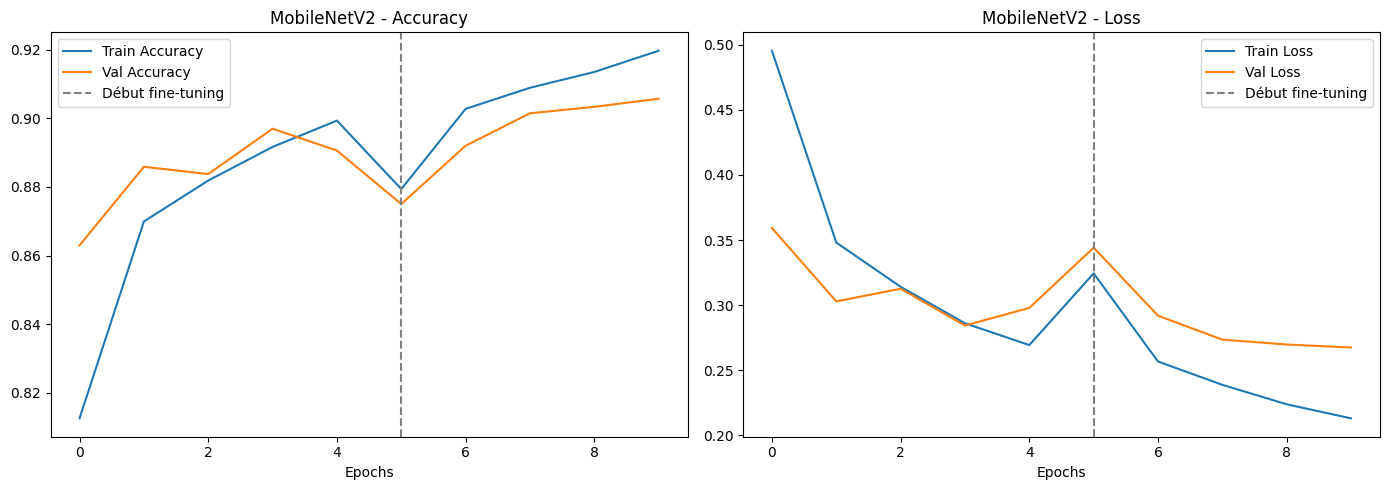

133/133 ━━━━━━━━━━━━━━━━━━━━ 23s 143ms/step

Rapport de classification - MobileNetV2
                 precision    recall  f1-score   support

          COVID       0.95      0.89      0.92       723
   Lung_Opacity       0.88      0.85      0.87      1203
         Normal       0.90      0.93      0.92      2038
Viral Pneumonia       0.93      0.96      0.94       269

       accuracy                           0.91      4233
      macro avg       0.92      0.91      0.91      4233
   weighted avg       0.91      0.91      0.91      4233



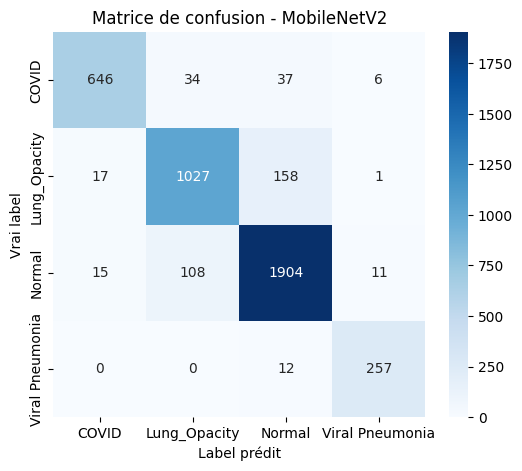

{'model': 'MobileNetV2', 'accuracy': 0.9057406094968108, 'precision': 0.9060470178733953, 'recall': 0.9057406094968108, 'f1_score': 0.9055364271102161, 'auc': np.float64(0.9830868374686927)}


In [12]:
plot_finetuning_curves(history_mobilenet, 'MobileNetV2')
metrics_mobilenet = evaluate_model(model_mobilenet, eval_gen_mobilenet, 'MobileNetV2')
print(metrics_mobilenet)

In [11]:
model_mobilenet.save('/kaggle/working/mobilenetv2_covid_model.keras')